# 1. Import Libraries and load dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"D:\Dataset_for_projects\APY_data.csv")

print(df.head())

                        State District       Crop  Crop_Year       Season  \
0  Andaman and Nicobar Island  NICOBARS  Arecanut       2007  Kharif        
1  Andaman and Nicobar Island  NICOBARS  Arecanut       2007  Rabi          
2  Andaman and Nicobar Island  NICOBARS  Arecanut       2008  Autumn        
3  Andaman and Nicobar Island  NICOBARS  Arecanut       2008  Summer        
4  Andaman and Nicobar Island  NICOBARS  Arecanut       2009  Autumn        

    Area   Production  Yield  
0  2439.6      3415.0   1.40  
1  1626.4      2277.0   1.40  
2  4147.0      3060.0   0.74  
3  4147.0      2660.0   0.64  
4  4153.0      3120.0   0.75  


# 2. Check Dataset details for analysis

In [6]:
print("Dataset shape : ",df.shape)
print("Dataset information : ")
print(df.info())

Dataset shape :  (345336, 8)
Dataset information : 
<class 'pandas.DataFrame'>
RangeIndex: 345336 entries, 0 to 345335
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   State       345336 non-null  str    
 1   District    345336 non-null  str    
 2   Crop        345327 non-null  str    
 3   Crop_Year   345336 non-null  int64  
 4   Season      345336 non-null  str    
 5   Area        345336 non-null  float64
 6   Production  340388 non-null  float64
 7   Yield       345336 non-null  float64
dtypes: float64(3), int64(1), str(4)
memory usage: 21.1 MB
None


In [16]:
# Check null value and duplicates
print("Null Values in Dataset :")
print(df.isnull().sum())

print("\nDuplicates in dataset :")
print(df.duplicated().sum())

Null Values in Dataset :
State            0
District         0
Crop             9
Crop_Year        0
Season           0
Area             0
Production    4948
Yield            0
dtype: int64

Duplicates in dataset :
0


In [18]:
(df.isnull().sum() / len(df) * 100).round(2)

State         0.00
District      0.00
Crop          0.00
Crop_Year     0.00
Season        0.00
Area          0.00
Production    1.43
Yield         0.00
dtype: float64

In [19]:
# Drop the null columns
df.dropna(inplace=True)

In [21]:
print("Null Values in Dataset :")
print(df.isnull().sum())

print("\nDuplicates in dataset :")
print(df.duplicated().sum())

print("\nDataset shape : ",df.shape)

Null Values in Dataset :
State         0
District      0
Crop          0
Crop_Year     0
Season        0
Area          0
Production    0
Yield         0
dtype: int64

Duplicates in dataset :
0

Dataset shape :  (340383, 8)


# 3. Descriptive Statistical Analysis

In [26]:
print(df.describe())

           Crop_Year         Area     Production          Yield
count  340383.000000  3.403830e+05  3.403830e+05  340383.000000
mean     2008.884815  1.182641e+04  9.584867e+05      80.578840
std         6.574730  4.612680e+04  2.153083e+07     923.273309
min      1997.000000  8.000000e-03  0.000000e+00       0.000000
25%      2003.000000  8.000000e+01  8.700000e+01       0.570000
50%      2009.000000  5.630000e+02  7.180000e+02       1.030000
75%      2015.000000  4.258000e+03  7.182000e+03       2.500000
max      2020.000000  8.580100e+06  1.597800e+09   43958.330000


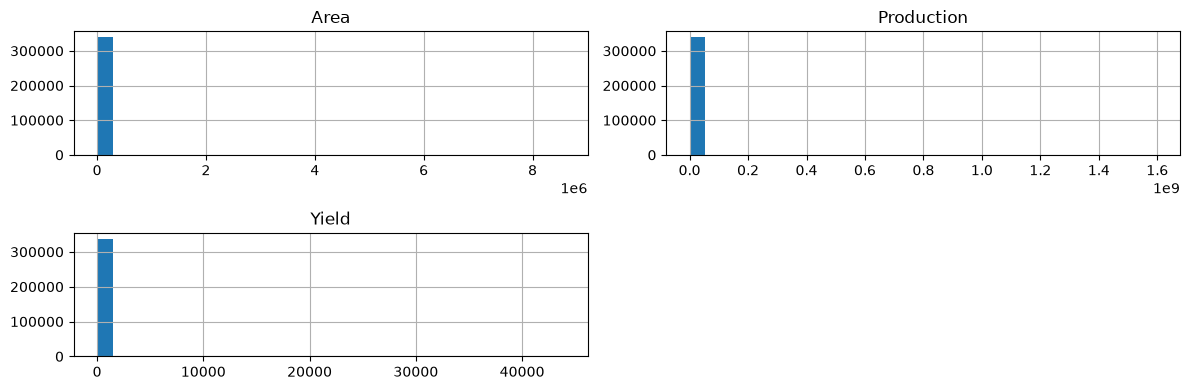

In [89]:
# Visualize the distributions
df[["Area","Production","Yield"]].hist(figsize=(12,4),bins=30)

plt.tight_layout()
plt.show()

In [92]:
# Ouliers Calculation
columns = ["Area","Production","Yield"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)
    print("Lower limit : ",lower)
    print("Upper limit : ",upper)
    print("Outliers Count : ",len(outliers))
    print("Outliers percentage : ",round(len(outliers)/len(df)*100, 2), "%")
    print("-"*50)

Area
Lower limit :  -6187.0
Upper limit :  10525.0
Outliers Count :  56520
Outliers percentage :  16.6 %
--------------------------------------------------
Production
Lower limit :  -10555.5
Upper limit :  17824.5
Outliers Count :  60094
Outliers percentage :  17.65 %
--------------------------------------------------
Yield
Lower limit :  -2.3250000000000006
Upper limit :  5.3950000000000005
Outliers Count :  51392
Outliers percentage :  15.1 %
--------------------------------------------------


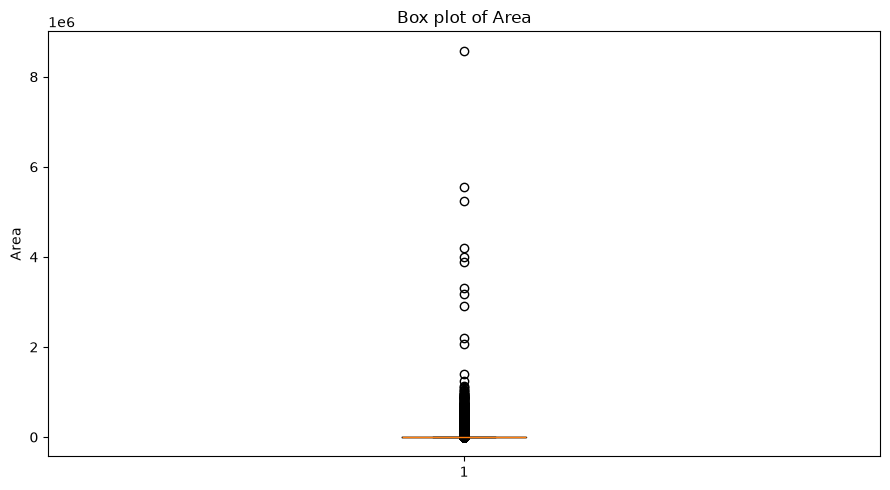

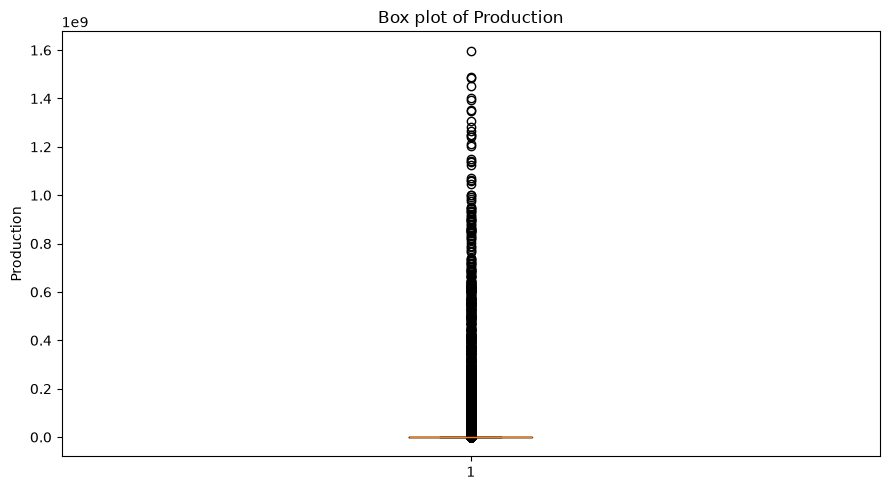

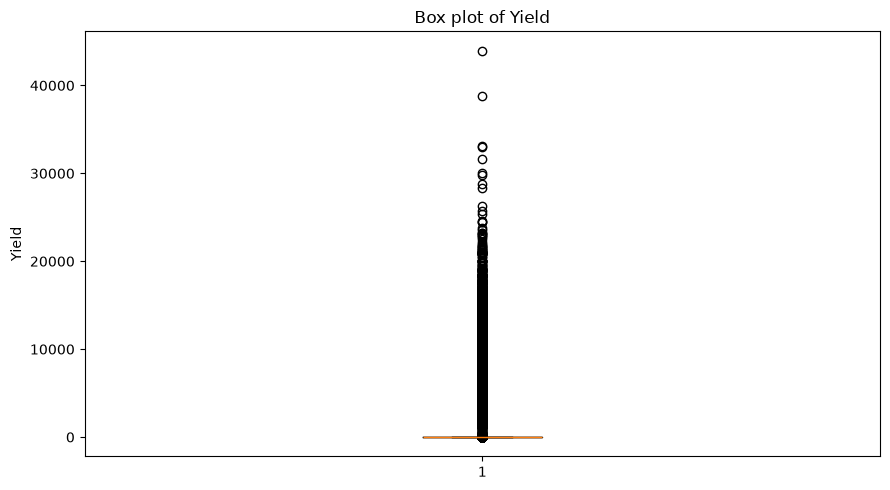

In [94]:
# Visualisation
for col in columns:
    plt.figure(figsize=(9,5))
    plt.boxplot(df[col])
    plt.title(f"Box plot of {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# 4. Check Correlation

In [32]:
corr = df[["Crop_Year","Area","Production","Yield"]].corr()

print(corr.round(3))

            Crop_Year   Area  Production  Yield
Crop_Year       1.000 -0.024       0.004  0.009
Area           -0.024  1.000       0.049  0.000
Production      0.004  0.049       1.000  0.437
Yield           0.009  0.000       0.437  1.000


# 5. Visualization of correlation matrix

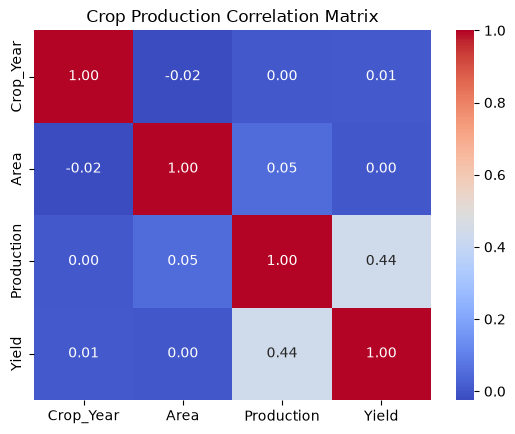

In [33]:
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Crop Production Correlation Matrix")
plt.show()

# 6. Yearly production analysis

In [34]:
yearly_production = df.groupby("Crop_Year")["Production"].sum()

print(yearly_production)

Crop_Year
1997    6.105673e+09
1998    7.887213e+09
1999    8.566817e+09
2000    9.666098e+09
2001    9.423699e+09
2002    1.251436e+10
2003    1.243323e+10
2004    1.392426e+10
2005    1.504934e+10
2006    1.581477e+10
2007    1.457585e+10
2008    1.627291e+10
2009    1.670823e+10
2010    1.208182e+10
2011    1.939837e+10
2012    1.318740e+10
2013    1.720176e+10
2014    1.788990e+10
2015    1.849115e+10
2016    1.652594e+10
2017    1.603249e+10
2018    1.806582e+10
2019    1.842530e+10
2020    1.017723e+07
Name: Production, dtype: float64


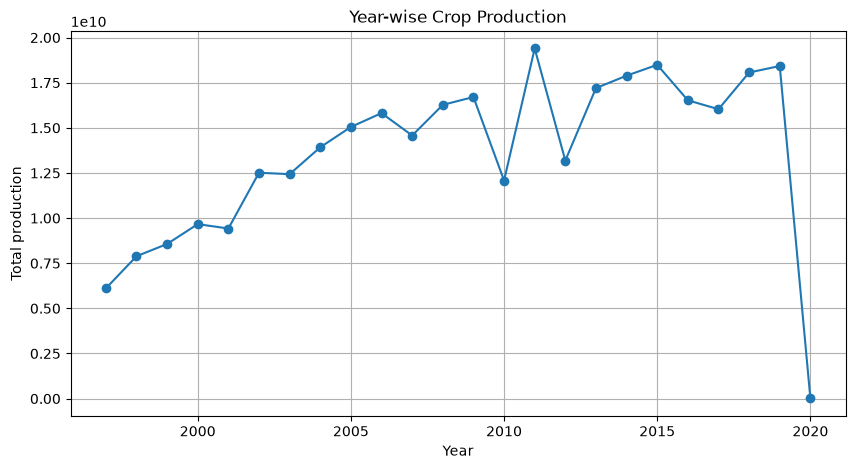

In [35]:
yearly_production.plot(kind="line", figsize=(10,5), marker="o")

plt.title("Year-wise Crop Production")
plt.xlabel("Year")
plt.ylabel("Total production")
plt.grid(True)
plt.show()

# 8. Check the numbers of records yearly

In [37]:
df.groupby("Crop_Year").size()

Crop_Year
1997     8548
1998    12010
1999    12936
2000    13483
2001    13237
2002    14042
2003    14512
2004    13888
2005    13774
2006    14313
2007    14410
2008    14812
2009    14947
2010    14621
2011    15827
2012    15042
2013    15962
2014    15381
2015    16222
2016    17263
2017    17787
2018    18047
2019    19000
2020      319
dtype: int64

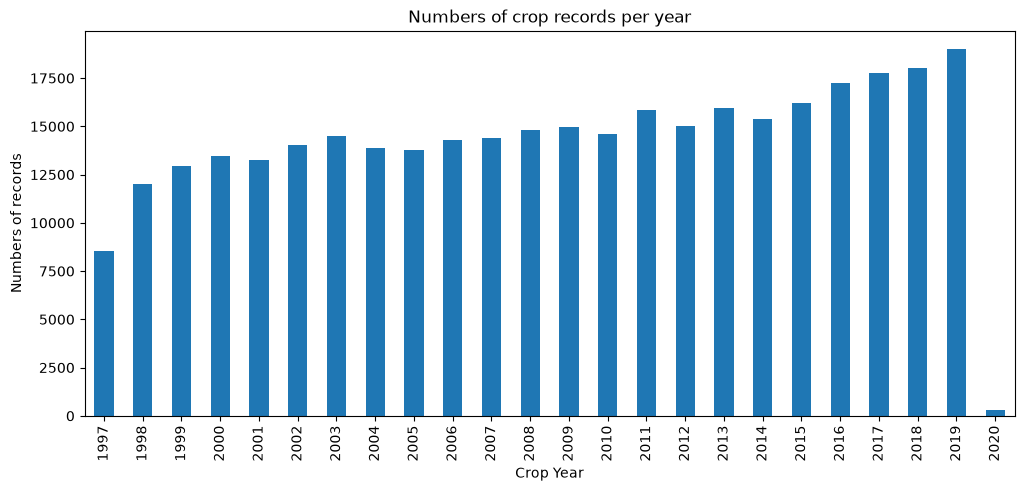

In [38]:
# Visualize yearly counts
yearly_count = df.groupby("Crop_Year").size()

yearly_count.plot(kind="bar", figsize=(12,5))

plt.title("Numbers of crop records per year")
plt.xlabel("Crop Year")
plt.ylabel("Numbers of records")
plt.show()

# 9. Crop-wise production analysis

In [55]:
top_crops = df.groupby("Crop")["Production"].sum().nlargest(5)
top_crops = top_crops.sort_values(ascending=False)
print(top_crops)

Crop
Coconut      3.108048e+11
Sugarcane    7.249507e+09
Rice         2.236428e+09
Wheat        2.007360e+09
Potato       6.323157e+08
Name: Production, dtype: float64


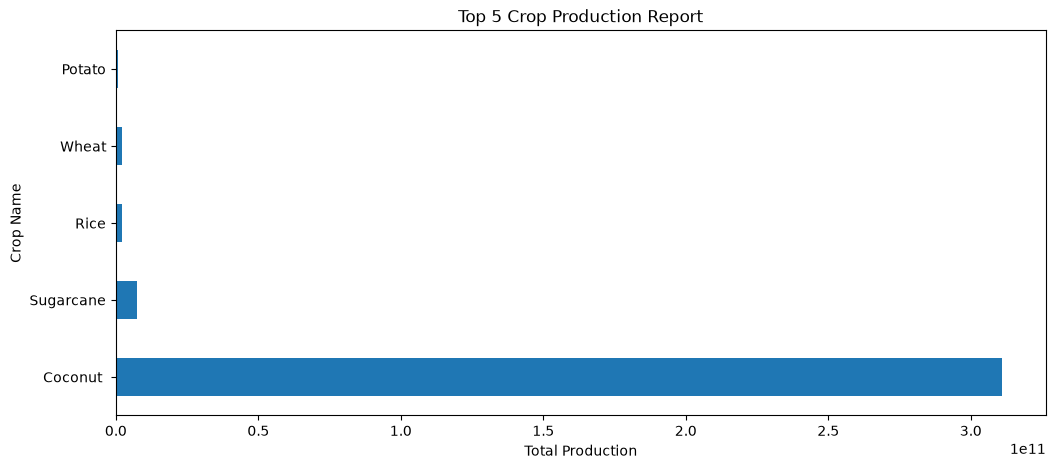

In [56]:
top_crops.plot(kind="barh", figsize=(12,5))

plt.title("Top 5 Crop Production Report")
plt.xlabel("Total Production")
plt.ylabel("Crop Name")
plt.show()

# 10. Crop-wise yeild analysis

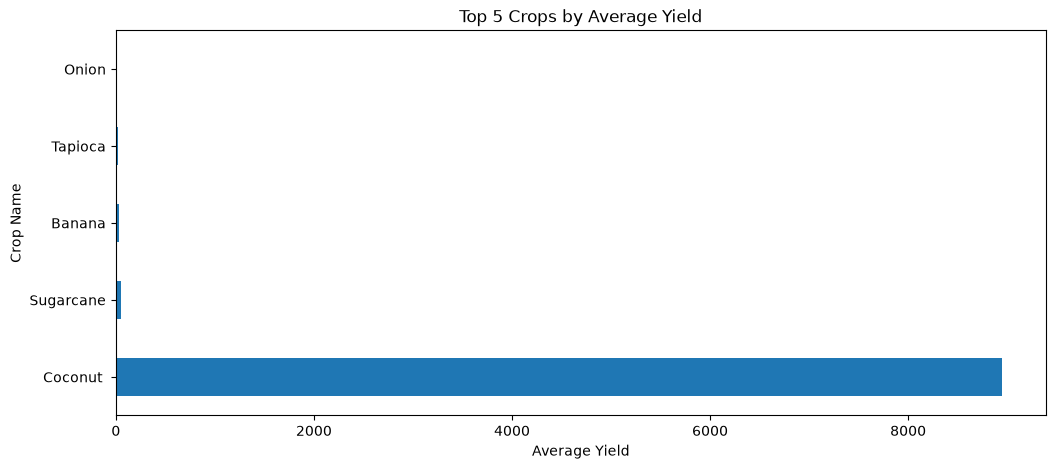

In [60]:
top_yeild = df.groupby("Crop")["Yield"].mean().nlargest(5)
top_yeild = top_yeild.sort_values(ascending=False)

top_yeild.plot(kind="barh", figsize=(12,5))

plt.title("Top 5 Crops by Average Yield")
plt.xlabel("Average Yield")
plt.ylabel("Crop Name")
plt.show()

In [61]:
top_yeild = df.groupby("Crop")["Yield"].mean().nlargest(10)
print(top_yeild)

Crop
Coconut         8943.243196
Sugarcane         56.188318
Banana            29.756524
Tapioca           18.938542
Onion             13.245736
Potato            13.182370
Jute               9.775411
Sweet potato       9.421494
Cashewnut          7.002916
Ginger             6.686928
Name: Yield, dtype: float64


# 11. Season-wise production analysis

In [63]:
seasonwise_prod = df.groupby("Season")["Production"].sum()
seasonwise_prod  = seasonwise_prod .sort_values(ascending=False)
print(seasonwise_prod )

Season
Whole Year     3.165636e+11
Kharif         5.622335e+09
Rabi           3.150455e+09
Winter         5.877505e+08
Summer         2.437629e+08
Autumn         8.464151e+07
Name: Production, dtype: float64


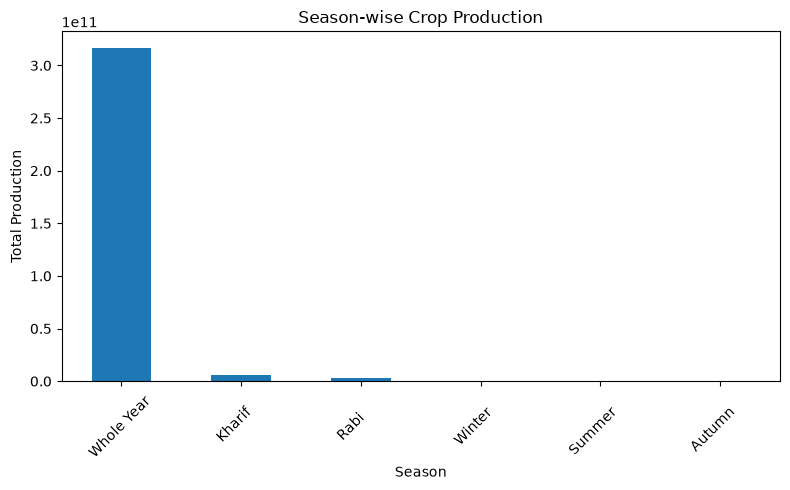

In [64]:
seasonwise_prod.plot(kind="bar", figsize=(8, 5))

plt.title("Season-wise Crop Production")
plt.xlabel("Season")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Season
Kharif         5.622335e+09
Rabi           3.150455e+09
Winter         5.877505e+08
Summer         2.437629e+08
Autumn         8.464151e+07
Name: Production, dtype: float64


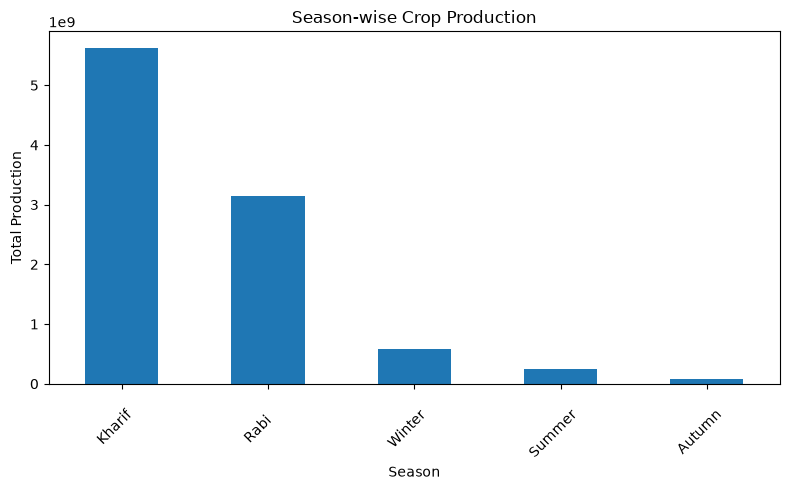

In [65]:
seasonwise_prod_tail = df.groupby("Season")["Production"].sum().nsmallest(5)
seasonwise_prod_tail = seasonwise_prod_tail .sort_values(ascending=False)
print(seasonwise_prod_tail)

seasonwise_prod_tail.plot(kind="bar", figsize=(8, 5))

plt.title("Season-wise Crop Production")
plt.xlabel("Season")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 11. Statewise production analysis

State
Kerala                        1.297006e+11
Tamil Nadu                    7.805176e+10
Karnataka                     6.377280e+10
Andhra Pradesh                2.607622e+10
West Bengal                   8.941179e+09
Uttar Pradesh                 4.442585e+09
Assam                         3.637715e+09
Goa                           2.193998e+09
Andaman and Nicobar Island    2.053350e+09
Maharashtra                   1.878565e+09
Name: Production, dtype: float64


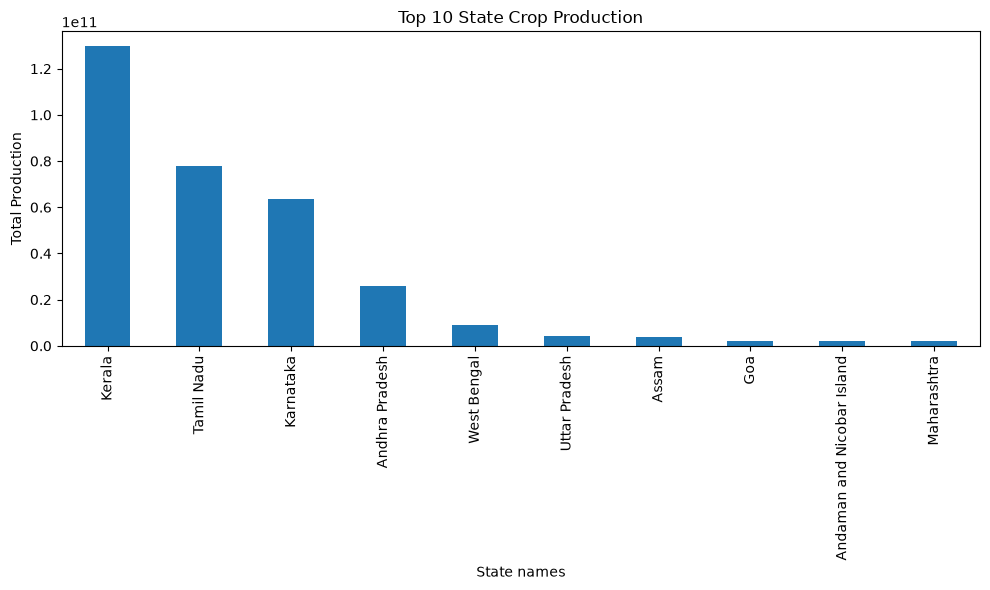

In [70]:
statewise_prod= df.groupby("State")["Production"].sum().nlargest(10)
statewise_prod = statewise_prod .sort_values(ascending=False)
print(statewise_prod)

statewise_prod.plot(kind="bar", figsize=(10, 6))

plt.title("Top 10 State Crop Production")
plt.xlabel("State names")
plt.ylabel("Total Production")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 12. Seasonwise Average yeild

Season
Winter         6.045748
Summer         3.356722
Autumn         2.453017
Kharif         2.403679
Rabi           2.248831
Name: Yield, dtype: float64


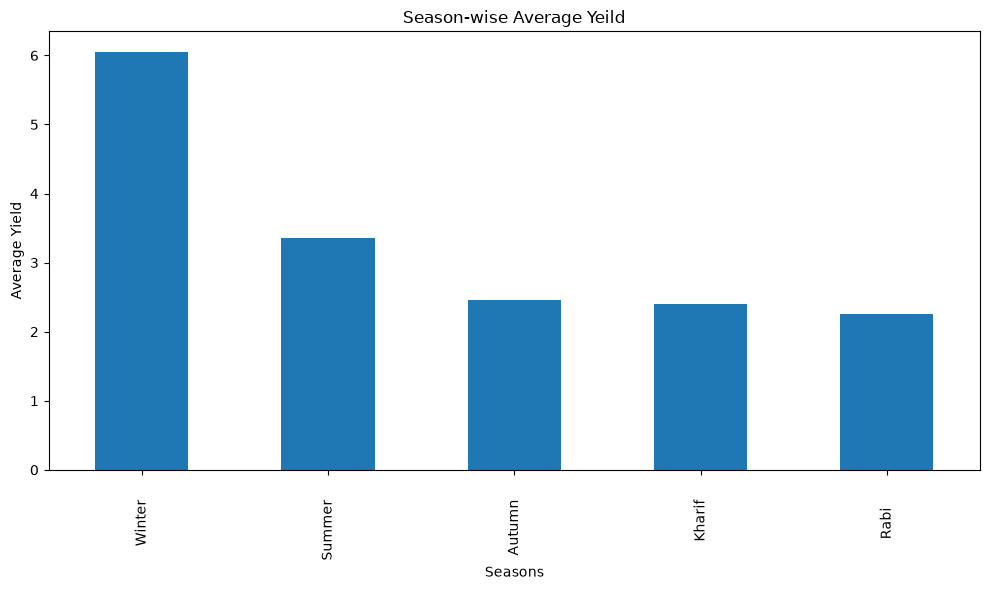

In [81]:
seasonwise_yeild = df.groupby("Season")["Yield"].mean().nsmallest(5)
seasonwise_yeild  = seasonwise_yeild .sort_values(ascending=False)
print(seasonwise_yeild )

seasonwise_yeild.plot(kind="bar", figsize=(10, 6))

plt.title("Season-wise Average Yeild")
plt.xlabel("Seasons")
plt.ylabel("Average Yield")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 13. Statewise average yeild analysis

State
Puducherry                    782.739501
Kerala                        443.073522
West Bengal                   431.109091
Goa                           368.853801
Andaman and Nicobar Island    327.401720
Tamil Nadu                    311.408376
Assam                         228.842688
Andhra Pradesh                215.474705
Karnataka                     158.464365
Telangana                      22.747624
Name: Yield, dtype: float64


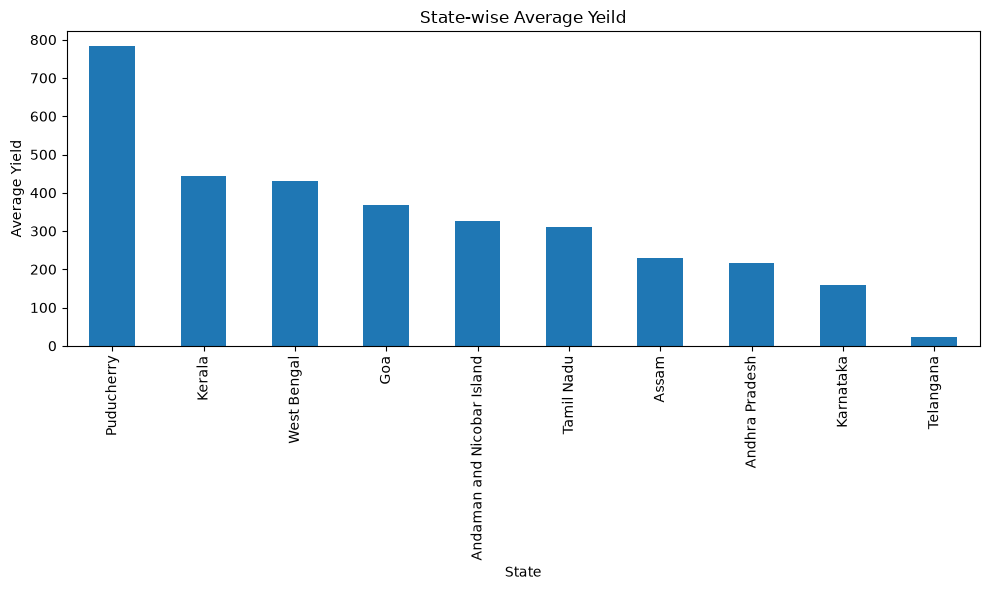

In [80]:
statewise_yeild = df.groupby("State")["Yield"].mean().nlargest(10)
statewise_yeild  = statewise_yeild .sort_values(ascending=False)
print(statewise_yeild )

statewise_yeild.plot(kind="bar", figsize=(10, 6))

plt.title("State-wise Average Yeild")
plt.xlabel("State")
plt.ylabel("Average Yield")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 14. Top 10 district production

District
TUMAKURU              2.076831e+10
KOZHIKODE             2.036689e+10
MALAPPURAM            1.962187e+10
COIMBATORE            1.766416e+10
THIRUVANANTHAPURAM    1.322358e+10
KANNUR                1.290873e+10
THRISSUR              1.289353e+10
EAST GODAVARI         1.266359e+10
KASARAGOD             1.116727e+10
KOLLAM                9.144800e+09
Name: Production, dtype: float64


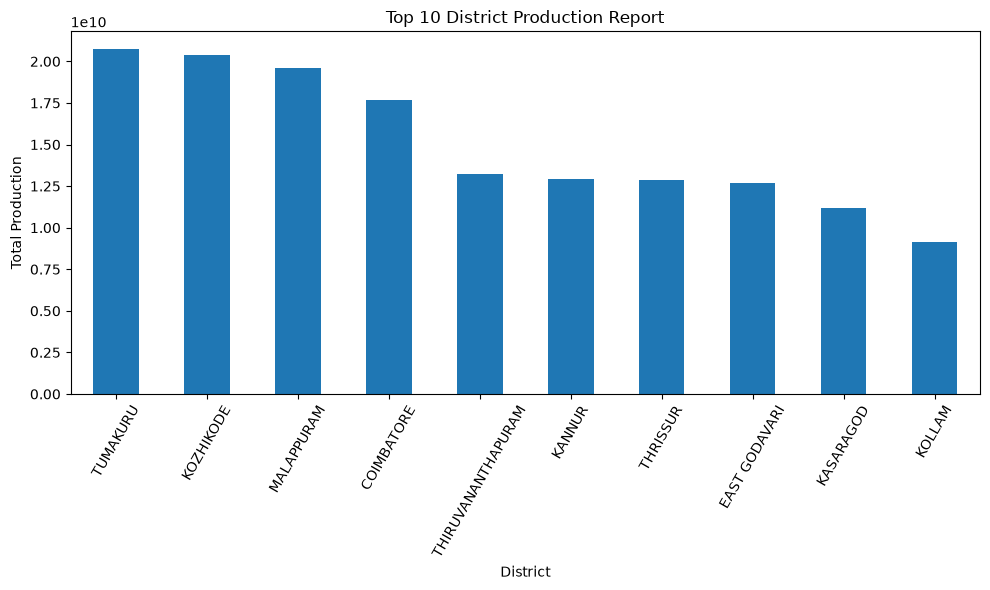

In [84]:
dist_prod = df.groupby("District")["Production"].sum().nlargest(10)
dist_prod  = dist_prod .sort_values(ascending=False)
print(dist_prod )

dist_prod.plot(kind="bar", figsize=(10, 6))

plt.title("Top 10 District Production Report")
plt.xlabel("District")
plt.ylabel("Total Production")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# 15. Top 10 Crops by Total Cultivated Area


Crop
Rice                 9.950024e+08
Wheat                6.644910e+08
Cotton(lint)         2.322117e+08
Soyabean             2.044099e+08
Bajra                1.989363e+08
Maize                1.802871e+08
Jowar                1.785626e+08
Gram                 1.769855e+08
Groundnut            1.325703e+08
Rapeseed &Mustard    1.300855e+08
Name: Area, dtype: float64


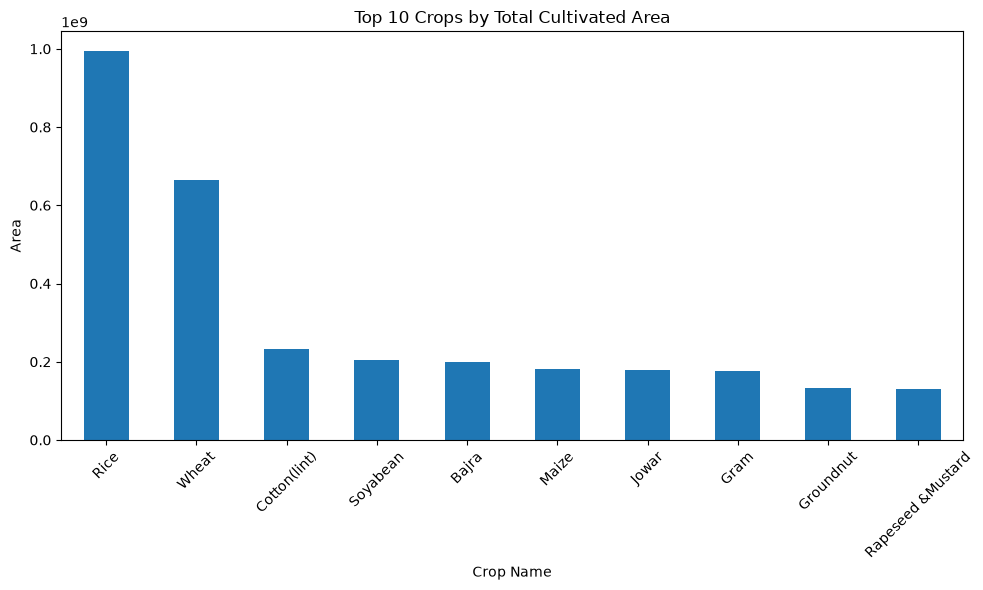

In [86]:
crop_area = df.groupby("Crop")["Area"].sum().nlargest(10)
crop_area  = crop_area .sort_values(ascending=False)
print(crop_area )

crop_area.plot(kind="bar", figsize=(10, 6))

plt.title("Top 10 Crops by Total Cultivated Area")
plt.xlabel("Crop Name")
plt.ylabel("Area")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Key Findings :

**Year-wise Production:** Total crop production generally increased over much of the study period, although fluctuations occurred between years. The production figure for 2020 was unusually low because the dataset contained far fewer records for that year.

**Crop-wise Production:** Rice and wheat were among the leading crops by total recorded production.

**Average Crop Yield:** Coconut had the highest average yield among the crops analyzed.

**State-wise Production:** Kerala recorded the highest total crop production among the states in the dataset, followed by Tamil Nadu and Karnataka.

**State-wise Average Yield:** Puducherry recorded the highest average yield among the states analyzed, followed by Kerala and West Bengal.

**District-wise Production:** Tumakuru recorded the highest total crop production among the districts analyzed, followed by Kozhikode and Malappuram.

**Cultivated Area:** Rice occupied the largest total recorded cultivated area, followed by wheat and cotton.

**Outlier Analysis:** The IQR method identified potential outliers in all three numerical variables. Area had 56,520 potential outliers (16.60%),   Production had 60,094 (17.65%), and Yield had 51,392 (15.10%).These values may be real or errors, so we should check them before removing them.

**Correlation Analysis:** Production and yield showed a moderate positive relationship. The other numerical variables examined had weak relationships with one another.

**Data Quality:** Missing values were removed before the analysis. The results also highlighted the importance of checking unusual values and differences in the number of records across years.

## Final Conclusion :

This project analyzed crop production data across different years, states, districts, crops, and seasons using Python. The analysis included data cleaning, descriptive statistics, data distribution, correlation analysis, yearly production trends, and comparisons of crop production, average yield, and cultivated area.

The results showed considerable differences in crop production and average yield across crops and locations. Rice and wheat were among the leading crops by total production, while Kerala recorded the highest total production among the states analyzed. The analysis also identified districts with high recorded production and crops occupying the largest cultivated areas.

Overall, this project provides a useful overview of the available agricultural data and demonstrates how statistical analysis and visualizations can help identify patterns, compare agricultural performance, and support a better understanding of crop production.